# Kural — Complaint Theme Discovery (NLP Text Analysis)

This notebook applies natural language processing (NLP) to discover recurring complaint themes across 117,214 financial consumer narratives.

### Overview
Reading thousands of unstructured complaint narratives manually is impractical. Unsupervised topic modeling surfaces latent patterns directly from written consumer text. Using TF-IDF vectorization and Non-negative Matrix Factorization (NMF), we extract 16 candidate complaint themes without manual pre-labeling.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Connect to project src
sys.path.append(str(Path('../src').resolve()))
from text_analysis import (
    prepare_nlp_text,
    fit_topic_model,
    extract_topic_keywords,
    assign_topics,
    generate_topic_summary_tables,
    generate_topic_visualizations
)

figures_dir = Path('../outputs/figures')
tables_dir = Path('../outputs/tables')
data_path = Path('../data/processed/complaints_with_topics.csv.gz')

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"Data path exists: {data_path.exists()}")

Data path exists: True


## Text Preparation

Before modeling, complaint text undergoes targeted preprocessing in `src/text_analysis.py`:
1. **CFPB Redaction Removal:** Strips masking tokens such as `XXXX`, `XX/XX/XXXX`, and isolated `x` characters.
2. **Amount Placeholder Cleaning:** Removes CFPB amount redactions (`{$0.00}`, `{$.00}`) and strips dangling cents `.00` from numeric values so currency amounts do not leave trailing zero artifacts.
3. **Zero-Only Token Stripping:** Standalone tokens consisting purely of zeros (`0`, `00`, `000`) are eliminated, preventing artifacts such as `00 past` or `balance 00` from polluting topic keywords.
4. **Financial Vocabulary & Meaningful Numbers Preservation:** Statutory numbers (`609`), delinquency durations (`30` days), and core financial terms (`credit`, `debt`, `mortgage`, `interest`, `fee`) are preserved.
5. **Safe Handling of Null and Unassigned Text:** Empty texts, texts with no usable vocabulary, and zero-strength NMF vectors receive `unassigned` with weight `0.0`.

In [2]:
# Load processed complaints with assigned topics
df = pd.read_csv(data_path)
print(f"Loaded dataset: {len(df):,} complaints, {len(df.columns)} columns.")

# Display summary of assigned topic IDs and weights without publishing raw complaint narratives
print("\n--- Sample Topic Assignments (Metadata only, narrative text omitted for privacy) ---")
display(df[['complaint_id', 'product', 'topic_id', 'topic_weight']].head(5))

print("\n--- Topic Weight Summary Statistics ---")
display(df[['topic_weight']].describe())

Loaded dataset: 117,214 complaints, 28 columns.

--- Sample Topic Assignments (Metadata only, narrative text omitted for privacy) ---


,complaint_id,product,topic_id,topic_weight
0,3384392,Debt collection,topic_08,0.046695
1,3417821,"Credit reporting, credit repair services, or o...",topic_06,0.027434
2,3433198,Debt collection,topic_07,0.038669
3,3366475,"Money transfer, virtual currency, or money ser...",topic_04,0.012018
4,3385399,Debt collection,topic_08,0.034564



--- Topic Weight Summary Statistics ---


,topic_weight
count,117214.000000
mean,0.035585
std,0.027155
min,0.000000
25%,0.021705
50%,0.029573
75%,0.040514
max,0.249935


## Topic Modeling Configuration

Topic discovery relies on standard TF-IDF representation and Non-negative Matrix Factorization (NMF):
- **TF-IDF Vectorization:** Unigrams and bigrams (`ngram_range=(1, 2)`), English stop words removed, `min_df=10`, `max_df=0.85`, `max_features=15000`, and `sublinear_tf=True`.
- **NMF Solver:** $k = 16$ candidate topics, deterministic Non-negative Double Singular Value Decomposition (`init="nndsvda"`), `random_state=42`, and `max_iter=350`.
- **Distinct Narrative Training:** Fitted on 101,796 distinct prepared narratives to prevent repetitive dispute templates from dominating vocabulary extraction, then assigned across all 117,214 complaints.

## Topic Results

Below we inspect the representative keywords and complaint distributions across the 16 candidate topics and unassigned complaints.

=== TOPIC KEYWORDS (TOP 12 REPRESENTATIVE TERMS) ===


,topic_id,top_keywords,complaint_count
0,topic_01,"told, called, said, did, asked, received, serv...",7291
1,topic_02,"report, credit report, credit, removed, remove...",11723
2,topic_03,"reporting, harming, harming credit, attached c...",2141
3,topic_04,"account, bank, closed, checking, bank america,...",9244
4,topic_05,"loan, loans, student, payments, navient, stude...",7468
5,topic_06,"theft, identity, identity theft, victim, victi...",5369
6,topic_07,"number, phone, calls, calling, times, phone nu...",5776
7,topic_08,"debt, collection, company, agency, collection ...",12491
8,topic_09,"late, payment, payments, late payment, days la...",7110
9,topic_10,"card, credit card, credit, charges, cards, cha...",9343



=== TOPIC DISTRIBUTION (ALL 117,214 COMPLAINTS) ===


,topic_id,complaint_count,percentage
0,topic_01,7291,6.22
1,topic_02,11723,10.00
2,topic_03,2141,1.83
3,topic_04,9244,7.89
4,topic_05,7468,6.37
5,topic_06,5369,4.58
6,topic_07,5776,4.93
7,topic_08,12491,10.66
8,topic_09,7110,6.07
9,topic_10,9343,7.97


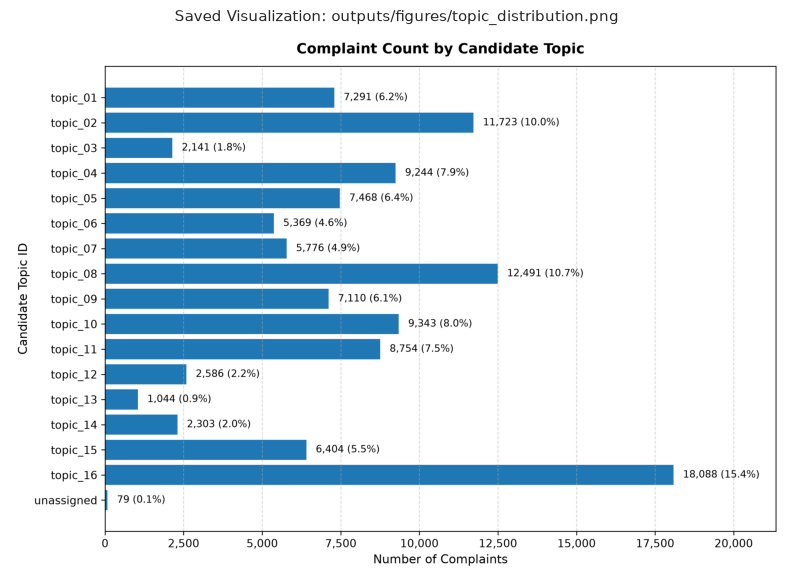

In [3]:
# Load Topic Keywords and Distribution Tables
df_keywords = pd.read_csv(tables_dir / 'topic_keywords.csv')
df_dist = pd.read_csv(tables_dir / 'topic_distribution.csv')

print("=== TOPIC KEYWORDS (TOP 12 REPRESENTATIVE TERMS) ===")
display(df_keywords)

print("\n=== TOPIC DISTRIBUTION (ALL 117,214 COMPLAINTS) ===")
display(df_dist)

# Display Topic Distribution Figure
dist_img = plt.imread(figures_dir / 'topic_distribution.png')
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(dist_img)
ax.axis('off')
plt.title('Saved Visualization: outputs/figures/topic_distribution.png', fontsize=11, pad=10)
plt.show()

## Business Comparisons & Issue Alignment

To evaluate how well mathematical topics reflect operational reality, we compare candidate topics against product categories, recorded company relief rates, and the CFPB's source `issue` categories.

=== TOPICS AND RECORDED RELIEF ===


,topic_id,total_complaints,complaints_with_recorded_relief,recorded_relief_percentage
0,topic_01,7291,1357,18.61
1,topic_02,11723,2863,24.42
2,topic_03,2141,302,14.11
3,topic_04,9244,2357,25.50
4,topic_05,7468,707,9.47
5,topic_06,5369,1570,29.24
6,topic_07,5776,1183,20.48
7,topic_08,12491,1258,10.07
8,topic_09,7110,1086,15.27
9,topic_10,9343,2369,25.36



=== SAMPLE TOPIC BY PRODUCT BREAKDOWN ===


,product,topic_id,complaint_count,percentage
0,Checking or savings account,topic_04,4557,65.90
1,Checking or savings account,topic_01,882,12.75
2,Checking or savings account,topic_14,660,9.54
3,Checking or savings account,topic_10,328,4.74
4,Checking or savings account,topic_07,192,2.78
5,Checking or savings account,topic_16,102,1.48
6,Checking or savings account,topic_06,48,0.69
7,Checking or savings account,topic_09,30,0.43
8,Checking or savings account,topic_11,26,0.38
9,Checking or savings account,topic_15,22,0.32



=== TOPIC SOURCE ISSUE ALIGNMENT (TOP 3 ISSUES PER TOPIC) ===


,topic_id,issue,complaint_count,percentage_within_topic
0,topic_01,Managing an account,554,7.60
1,topic_01,Problem with a purchase shown on your statement,547,7.50
2,topic_01,Incorrect information on your report,430,5.90
3,topic_02,Incorrect information on your report,6784,57.87
4,topic_02,Problem with a credit reporting company's inve...,1700,14.50
5,topic_02,Attempts to collect debt not owed,1016,8.67
6,topic_03,Problem with a credit reporting company's inve...,1825,85.24
7,topic_03,Incorrect information on your report,252,11.77
8,topic_03,Attempts to collect debt not owed,21,0.98
9,topic_04,Managing an account,2393,25.89


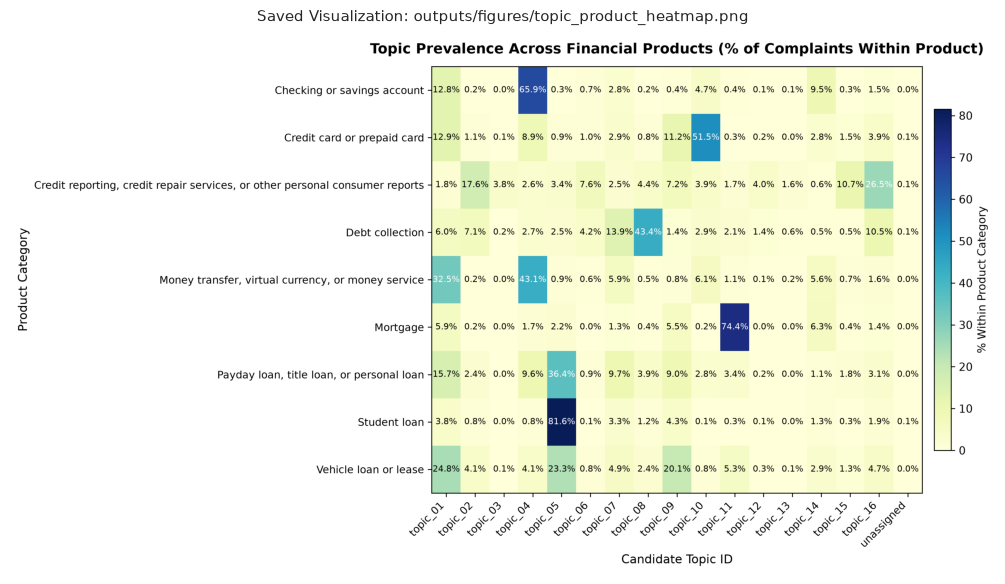

In [4]:
# Load Topic-Product, Topic-Relief, and Topic-Issue Alignment Tables
df_by_prod = pd.read_csv(tables_dir / 'topic_by_product.csv')
df_relief = pd.read_csv(tables_dir / 'topic_recorded_relief.csv')
df_align = pd.read_csv(tables_dir / 'topic_issue_alignment.csv')

print("=== TOPICS AND RECORDED RELIEF ===")
display(df_relief)

print("\n=== SAMPLE TOPIC BY PRODUCT BREAKDOWN ===")
display(df_by_prod.head(15))

print("\n=== TOPIC SOURCE ISSUE ALIGNMENT (TOP 3 ISSUES PER TOPIC) ===")
display(df_align.head(20))

# Display Topic-Product Heatmap Figure
heatmap_img = plt.imread(figures_dir / 'topic_product_heatmap.png')
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(heatmap_img)
ax.axis('off')
plt.title('Saved Visualization: outputs/figures/topic_product_heatmap.png', fontsize=11, pad=10)
plt.show()

## Initial Observations

Based strictly on the empirical outputs from the current model run:

1. **Complete Coverage and Unassigned Fallback:**
   - Out of 117,214 complaints, 117,135 (99.93%) are assigned to one of the 16 candidate NMF topics.
   - Exactly 79 complaints (0.07%) are mapped to `unassigned` due to empty prepared text or lack of usable TF-IDF vocabulary.
   - The total across candidate topics and unassigned complaints equals exactly 117,214.

2. **Elimination of Numeric Redaction Artifacts:**
   - Zero-only placeholders (`00`, `000`, `{$0.00}`) and artifact bigrams (`00 past`, `balance 00`, `past 00`) have been eliminated from all topic keywords.
   - In `topic_03`, keywords now focus purely on reporting disputes (*reporting, harming, harming credit, attached credit, incorrectly, past, partial account*).

3. **Strong Product Alignment Across Specific Domains:**
   - `topic_11` (*mortgage, loan, home, escrow, property, modification, foreclosure*) accounts for 74.37% (7,027) of Mortgage complaints.
   - `topic_05` (*loan, loans, student, payments, navient, student loan, school*) accounts for 81.55% (3,214) of Student loan complaints.
   - `topic_04` (*account, bank, closed, checking, bank america, funds, money*) accounts for 65.90% (4,557) of Checking or savings account complaints.
   - `topic_10` (*card, credit card, credit, charges, cards, score, balance*) accounts for 51.46% (5,954) of Credit card complaints.
   - `topic_08` (*debt, collection, company, agency, collect, owe, validation*) accounts for 43.42% (9,677) of Debt collection complaints.

4. **Multiple Granular Credit Reporting Themes:**
   - High-volume credit reporting complaints separate into distinct sub-themes supported by CFPB source issues:
     - `topic_02`: Inaccurate account removal disputes (*report, credit report, removed, remove, items*), with 57.87% under "Incorrect information on your report".
     - `topic_03`: Investigation disputes (*reporting, harming credit, incorrectly*), with 85.24% under "Problem with a credit reporting company's investigation into an existing problem".
     - `topic_06`: Identity theft and fraud disputes (*theft, identity, victim, fraudulent, police report*), with 66.42% under "Incorrect information on your report" and a 29.24% relief rate.
     - `topic_12`: Debt verification demands (*original, consumer contract, verifiable proof, listed, unverified*), with 68.10% under "Incorrect information on your report".
     - `topic_13`: Statutory FCRA blocking requirements (*consumer reporting agency, block, shall, section, subsection*), with a 37.36% recorded-relief rate.
     - `topic_15`: Unauthorized credit inquiries (*inquiry, inquiries, hard inquiry, unauthorized*), with 57.84% under "Improper use of your report".
     - `topic_16`: General credit reporting procedural disputes (*information, reporting, bureaus, dispute, fcra, letter*), representing the largest topic (18,088 complaints, 15.43%).

5. **Candidate Topics Requiring Operational Review:**
   - `topic_14`: Dominated by a specific financial institution (*wells, fargo, wells fargo, fargo bank, wf*) rather than a product or issue category.
   - `topic_01`: Captures generic customer service communications (*told, called, said, received, service, email, customer, spoke*) across multiple product types without a distinct financial grievance.
   - `topic_16`, `topic_02`, and `topic_12`: Exhibit overlapping dispute vocabulary that warrants consolidation review by the implementation lead.

## Model Limitations

The following constraints must be kept in mind when interpreting these topic modeling results:

- **Unsupervised Pattern Discovery vs. Ground Truth:** NMF identifies vocabulary co-occurrence patterns in written text; candidate topics do not represent verified administrative or legal classifications.
- **Absence of Ground-Truth Accuracy:** Because consumer narratives lack gold-standard topic labels, NMF does not yield a classification accuracy score.
- **Topic Overlap and Multi-Themed Complaints:** Real-world complaints frequently address multiple overlapping concerns (e.g., identity theft leading to debt collection calls). Forcing a single dominant topic assignment captures the strongest signal but simplifies complex multi-issue complaints.
- **Duplicate Narratives:** The presence of 10,854 duplicate narrative instances influences topic distribution, particularly in standardized dispute clusters.
- **Administrative Response Interpretation:** The `has_recorded_relief` indicator reflects company-reported administrative closure categories; it cannot be interpreted as proof of consumer satisfaction or case merit.
- **No Causal Inference:** Topic assignments correlate with certain response categories and products, but these associations do not prove that a topic causes a specific response outcome.